## Implementation of Linear regression using python

In [1]:
### Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# CSV files should be in the same folder as this notebook.
DATA_DIR = os.getcwd()
print("Working directory:", DATA_DIR)
print("CSV files found:", [f for f in os.listdir(DATA_DIR) if f.lower().endswith(".csv")])

Working directory: C:\Users\sanja\Data science 18\Lab-5
CSV files found: ['Food_Delivery_Times.csv', 'weight-height.csv']


## Load the dataset

In [2]:
import os
print("Current working directory:", os.getcwd())

Current working directory: C:\Users\sanja\Data science 18\Lab-5


In [3]:
# List files in the notebook's current folder (portable across computers)
print(os.listdir(os.getcwd()))

['.ipynb_checkpoints', 'Ex.No.6.ipynb', 'Food_Delivery_Times.csv', 'weight-height.csv']


In [4]:
# Find CSV files in the current folder and its subfolders
for root, dirs, files in os.walk(os.getcwd()):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\sanja\Data science 18\Lab-5\Food_Delivery_Times.csv
C:\Users\sanja\Data science 18\Lab-5\weight-height.csv
C:\Users\sanja\Data science 18\Lab-5\.ipynb_checkpoints\Food_Delivery_Times-checkpoint.csv
C:\Users\sanja\Data science 18\Lab-5\.ipynb_checkpoints\weight-height-checkpoint.csv


### Standardize numerical features

In [5]:
# Check that the provided height/weight dataset is available
weight_height_file = next(
    (f for f in os.listdir(os.getcwd())
     if f.lower().startswith("weight-height") and f.lower().endswith(".csv")),
    None
)
if weight_height_file is None:
    raise FileNotFoundError(
        "Place the supplied weight-height(1).csv file in the same folder as this notebook."
    )
print("Using dataset:", weight_height_file)

Using dataset: weight-height.csv


## Prepare dependant and independant variables

In [6]:
# Load the height and weight data; use Height as X and Weight as y
DF1 = pd.read_csv(weight_height_file)
X = DF1[["Height"]].to_numpy(dtype=float)
Y = DF1[["Weight"]].to_numpy(dtype=float)
print("X shape:", X.shape)
print("Y shape:", Y.shape)
Y.shape

X shape: (10000, 1)
Y shape: (10000, 1)


(10000, 1)

In [7]:
# Preview the first few rows
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


## Split the data into training and test set

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=67
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


In [10]:
# Create a linear regression model
model = LinearRegression()

Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [11]:
## Training  Linear regressions model 

In [12]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[6.14]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-246.41]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[388.89]


In [13]:
# Calculate evaluation metrics
Y_pred = model.predict(X_test)
mse = mean_squared_error(Y_test, Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)
print("Coefficient:", model.coef_[0][0])
print("Intercept:", model.intercept_[0])

Mean Squared Error (MSE): 187.03623939736042
Root Mean Squared Error (RMSE): 13.676119310585165
Mean Absolute Error (MAE): 11.184206753546729
R-squared (R2): 0.8135299373473699
Coefficient: 6.143039450393305
Intercept: -246.40909011275045


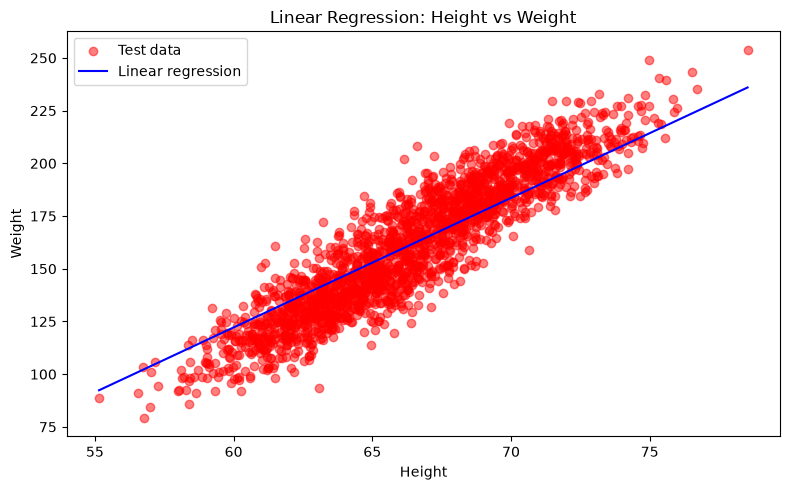

In [14]:
# Plot the test data and fitted regression line in ascending X order
order = np.argsort(X_test[:, 0])
plt.figure(figsize=(8, 5))
plt.scatter(X_test[:, 0], Y_test[:, 0], color="red", alpha=0.5, label="Test data")
plt.plot(X_test[order, 0], Y_pred[order, 0], color="blue", label="Linear regression")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.title("Linear Regression: Height vs Weight")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [15]:
# Load the height/weight dataset for manual gradient descent
df2 = pd.read_csv(weight_height_file)
x = df2["Height"].to_numpy(dtype=float).reshape(-1, 1)
y = df2["Weight"].to_numpy(dtype=float)
print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (10000, 1)
y shape: (10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [16]:
# Standardize the feature and target using Z-score normalization
X_scaled = (x - np.mean(x, axis=0)) / np.std(x, axis=0)
Y_scaled = (y - np.mean(y)) / np.std(y)
print("Standardized X mean:", X_scaled.mean())
print("Standardized y mean:", Y_scaled.mean())

Standardized X mean: -1.5916157281026244e-15
Standardized y mean: -4.5474735088646414e-17


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [17]:
# Add a bias column (intercept) to X
X = np.hstack((np.ones((X_scaled.shape[0], 1)), X_scaled))
X[:5]

array([[1.        , 1.75827913],
       [1.        , 0.56277158],
       [1.        , 1.82037531],
       [1.        , 1.25883516],
       [1.        , 0.82237664]])

In [18]:
# Initialize parameters and run batch gradient descent
theta = np.zeros(X.shape[1])
iterations = 1000
learningrate = 0.01
mseh = []
m = X.shape[0]

for i in range(iterations):
    y_pred = X @ theta
    errors = y_pred - Y_scaled
    mse_i = np.mean(errors ** 2)
    mseh.append(mse_i)
    gradient = (2 / m) * (X.T @ errors)
    theta -= learningrate * gradient

print("Final theta (bias, slope):", theta)
print("Final standardized MSE:", mseh[-1])
print("Initial standardized MSE:", mseh[0])

Final theta (bias, slope): [1.32222677e-15 8.44449232e-01]
Final standardized MSE: 0.2869054913354277
Initial standardized MSE: 1.0


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

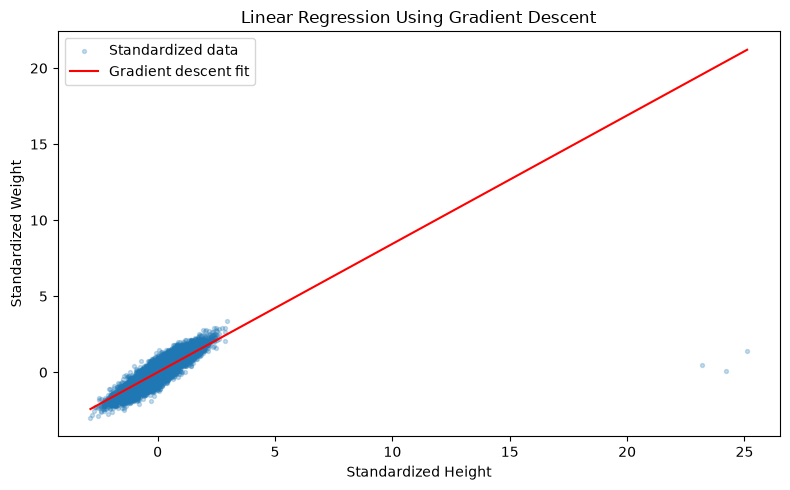

In [19]:
# Plot the fitted line in standardized coordinates
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], Y_scaled, s=8, alpha=0.25, label="Standardized data")
x_line = np.linspace(X_scaled.min(), X_scaled.max(), 100)
y_line = theta[0] + theta[1] * x_line
plt.plot(x_line, y_line, color="red", label="Gradient descent fit")
plt.xlabel("Standardized Height")
plt.ylabel("Standardized Weight")
plt.title("Linear Regression Using Gradient Descent")
plt.legend()
plt.tight_layout()
plt.show()

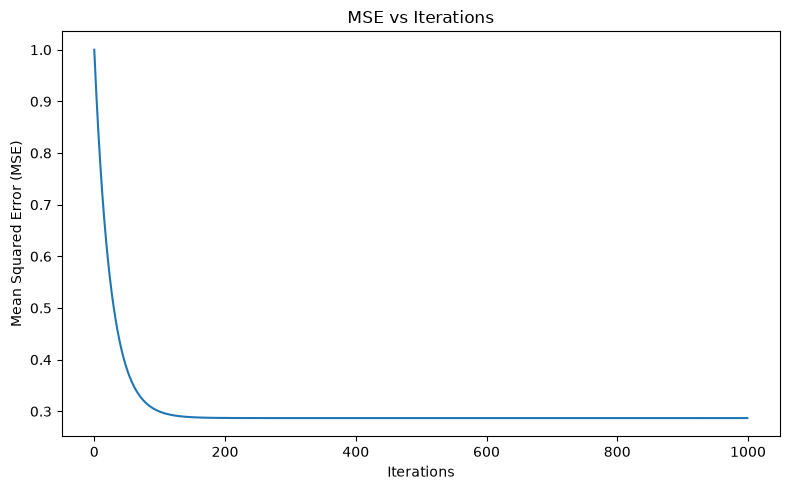

In [20]:
# Plot MSE over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(iterations), mseh)
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE vs Iterations")
plt.tight_layout()
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

Rows used: 1000
Features after encoding: ['Distance_km', 'Preparation_Time_min', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']
Mean Squared Error (MSE): 91.388
Root Mean Squared Error (RMSE): 9.56
Mean Absolute Error (MAE): 6.541
R-squared (R2): 0.823

Model coefficients:
Weather_Snowy            9.405060
Weather_Foggy            8.277228
Weather_Rainy            4.737342
Distance_km              2.938882
Weather_Windy            1.023424
Preparation_Time_min     0.965337
Traffic_Level_Medium    -6.550580
Traffic_Level_Low      -12.255669
dtype: float64
Intercept: 15.383


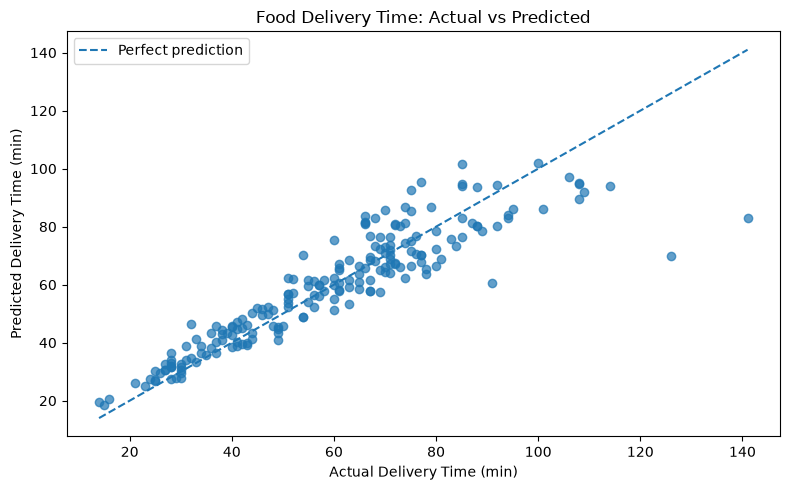

,Actual_Delivery_Time_min,Predicted_Delivery_Time_min
0,57.0,56.001536
1,67.0,57.750301
2,68.0,73.343011
3,28.0,33.090371
4,42.0,39.644224
5,47.0,49.742772
6,54.0,49.000784
7,28.0,32.095307
8,60.0,51.425882
9,68.0,82.929859


In [21]:
# Linear regression for food delivery time using the four specified features:
# Distance_km, Preparation_Time_min, Traffic_Level, and Weather.
food_file = next(
    (f for f in os.listdir(os.getcwd())
     if f.lower() == "food_delivery_times.csv"),
    None
)
if food_file is None:
    raise FileNotFoundError(
        "Place Food_Delivery_Times.csv in the same folder as this notebook."
    )

food_df = pd.read_csv(food_file)
features = ["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather"]
target = "Delivery_Time_min"
food_df = food_df[features + [target]].copy()

# Fill missing categorical values with the most frequent category.
for col in ["Traffic_Level", "Weather"]:
    food_df[col] = food_df[col].fillna(food_df[col].mode()[0])

# Encode categorical features using one-hot encoding.
food_X = pd.get_dummies(
    food_df[["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather"]],
    columns=["Traffic_Level", "Weather"],
    drop_first=True,
    dtype=int
)
food_y = food_df[target].astype(float)

X_train_food, X_test_food, y_train_food, y_test_food = train_test_split(
    food_X, food_y, test_size=0.2, random_state=67
)

food_model = LinearRegression()
food_model.fit(X_train_food, y_train_food)
food_pred = food_model.predict(X_test_food)

food_mse = mean_squared_error(y_test_food, food_pred)
food_rmse = np.sqrt(food_mse)
food_mae = mean_absolute_error(y_test_food, food_pred)
food_r2 = r2_score(y_test_food, food_pred)

print("Rows used:", len(food_df))
print("Features after encoding:", list(food_X.columns))
print("Mean Squared Error (MSE):", round(food_mse, 3))
print("Root Mean Squared Error (RMSE):", round(food_rmse, 3))
print("Mean Absolute Error (MAE):", round(food_mae, 3))
print("R-squared (R2):", round(food_r2, 3))
print("\nModel coefficients:")
print(pd.Series(food_model.coef_, index=food_X.columns).sort_values(ascending=False))
print("Intercept:", round(food_model.intercept_, 3))

# Compare actual and predicted delivery times.
plt.figure(figsize=(8, 5))
plt.scatter(y_test_food, food_pred, alpha=0.7)
limits = [
    min(y_test_food.min(), food_pred.min()),
    max(y_test_food.max(), food_pred.max())
]
plt.plot(limits, limits, linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Food Delivery Time: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

food_results = pd.DataFrame({
    "Actual_Delivery_Time_min": y_test_food.to_numpy(),
    "Predicted_Delivery_Time_min": food_pred
})
food_results.head(10)

In [ ]:
#THE END